In [7]:
%load_ext autoreload
%autoreload 2

import sys
from pathlib import Path

# Add project root to sys.path
project_root = Path.cwd().parent
if str(project_root) not in sys.path:
    sys.path.append(str(project_root))

import numpy as np
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, accuracy_score, f1_score, confusion_matrix

from src.audio_classification.utils import set_seed
from src.audio_classification.data import load_fma_metadata, get_audio_path, FMASpectrogramDataset
from src.audio_classification.features import extract_classical_features

import matplotlib.pyplot as plt
import seaborn as sns

# Set seed for reproducibility
set_seed(42)

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload
Global seed set to: 42


In [2]:
# Load FMA Metadata
metadata_dir = project_root / "data" / "raw" / "fma_metadata"
df_metadata = load_fma_metadata(str(metadata_dir))

print("Total tracks in dataset:", len(df_metadata))
print("\nGenre Breakdown:\n", df_metadata['genre'].value_counts())
print("\nOfficial Artist-Filtered Splits:\n", df_metadata['split'].value_counts())

Total tracks in dataset: 8000

Genre Breakdown:
 genre
Hip-Hop          1000
Pop              1000
Folk             1000
Experimental     1000
Rock             1000
International    1000
Electronic       1000
Instrumental     1000
Name: count, dtype: int64

Official Artist-Filtered Splits:
 split
training      6400
validation     800
test           800
Name: count, dtype: int64


In [3]:
audio_dir = str(project_root / "data" / "raw" / "fma_small")

# 1. Filter Train and Validation Splits
train_df = df_metadata[df_metadata['split'] == 'training'].reset_index(drop=True)
val_df = df_metadata[df_metadata['split'] == 'validation'].reset_index(drop=True)

print("Extracting classical features for training split...")
X_train = np.array([extract_classical_features(get_audio_path(audio_dir, tid)) for tid in train_df['track_id']])
y_train = train_df['genre'].values

print("Extracting classical features for validation split...")
X_val = np.array([extract_classical_features(get_audio_path(audio_dir, tid)) for tid in val_df['track_id']])
y_val = val_df['genre'].values

# 2. Train Random Forest Baseline Model
rf_baseline = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
rf_baseline.fit(X_train, y_train)

# 3. Evaluate Baseline Performance
y_pred = rf_baseline.predict(X_val)
print("\n--- Classical Baseline Performance (MFCCs + Random Forest) ---")
print(classification_report(y_val, y_pred))

Extracting classical features for training split...
Extracting classical features for validation split...

--- Classical Baseline Performance (MFCCs + Random Forest) ---
               precision    recall  f1-score   support

   Electronic       0.44      0.44      0.44       100
 Experimental       0.54      0.52      0.53       100
         Folk       0.61      0.66      0.63       100
      Hip-Hop       0.50      0.61      0.55       100
 Instrumental       0.42      0.39      0.40       100
International       0.54      0.52      0.53       100
          Pop       0.08      0.05      0.06       100
         Rock       0.61      0.73      0.66       100

     accuracy                           0.49       800
    macro avg       0.47      0.49      0.48       800
 weighted avg       0.47      0.49      0.48       800



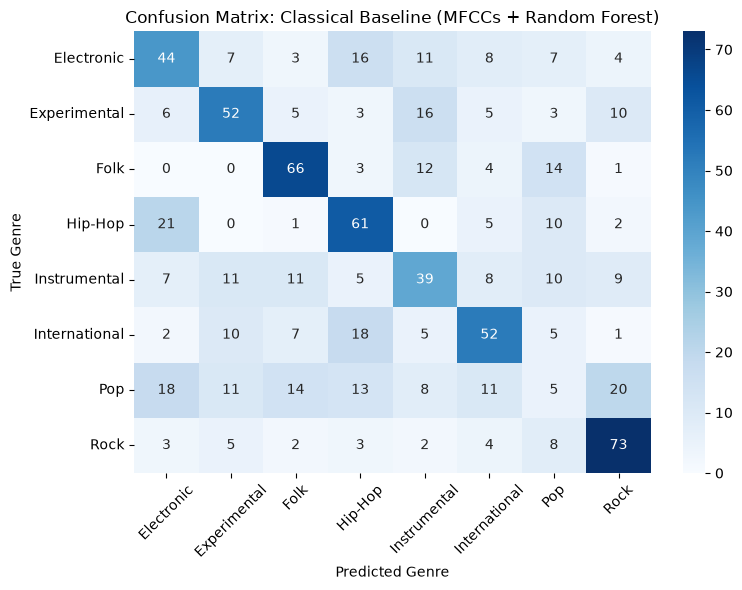

In [9]:
# 5. Plot Confusion Matrix Heatmap
labels = sorted(list(set(y_val)))
cm = confusion_matrix(y_val, y_pred, labels=labels)

plt.figure(figsize=(8, 6))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=labels,
    yticklabels=labels,
)
plt.title("Confusion Matrix: Classical Baseline (MFCCs + Random Forest)")
plt.xlabel("Predicted Genre")
plt.ylabel("True Genre")
plt.xticks(rotation=45)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()